# **Project 5: Monte Carlo Portfolio Risk Simulator**


# Simulate 10,000 one-year path for a 4-asset portfolio, then estimate volatility and Value-at-Risk.

## **Objective:**
- Simulates 10,000 one-year portfolio paths
- Uses 4 assets
- Uses 252 trading days
- Calculates simulated portfolio value
- Calculates volatility
- Calculates 95% Value-at-Risk (VaR)
- Displays a histogram of portfolio returns
- Uses a fixed random seed so results are reproducible



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## Set Random Seed

In [ ]:
SEED = 42
np.random.seed(SEED)

print(f"Random seed set to {SEED}")

Random seed set to 42


## Defining Portfolio Parameters

In [ ]:
# Number of simulations
N_SIMULATIONS = 10_000

# Trading days in one year
TRADING_DAYS = 252

# Number of assets
N_ASSETS = 4

# Initial portfolio value
INITIAL_VALUE = 1_000_000

# Asset names
assets = np.array([
    "Asset A",
    "Asset B",
    "Asset C",
    "Asset D"
])

# Portfolio weights
weights = np.array([
    0.30,
    0.25,
    0.25,
    0.20
])

# Daily expected returns
daily_mean = np.array([
    0.0005,
    0.0003,
    0.0004,
    0.0002
])

# Daily volatility
daily_volatility = np.array([
    0.012,
    0.015,
    0.010,
    0.018
])

print("Portfolio Parameters")
print("-" * 40)

for i in range(N_ASSETS):
    print(
        f"{assets[i]}: "
        f"Weight={weights[i]:.0%}, "
        f"Daily Mean={daily_mean[i]:.4%}, "
        f"Daily Volatility={daily_volatility[i]:.2%}"
    )

Portfolio Parameters
----------------------------------------
Asset A: Weight=30%, Daily Mean=0.0500%, Daily Volatility=1.20%
Asset B: Weight=25%, Daily Mean=0.0300%, Daily Volatility=1.50%
Asset C: Weight=25%, Daily Mean=0.0400%, Daily Volatility=1.00%
Asset D: Weight=20%, Daily Mean=0.0200%, Daily Volatility=1.80%


## Validate Portfolio Weights

In [ ]:
# Check whether portfolio weights sum to 100%
weight_sum = weights.sum()

print(f"Total portfolio weight: {weight_sum:.2f}")

if np.isclose(weight_sum, 1.0):
    print("✓ Portfolio weights are valid.")
else:
    print("✗ Portfolio weights must sum to 1.")

Total portfolio weight: 1.00
✓ Portfolio weights are valid.


## Our portfolio is:
Asset A	 -> 30%

Asset B -> 25%

Asset C	-> 25%

Asset D	-> 20%

Total(Assets) = 100%

##Portfolio Summary

In [ ]:
import pandas as pd

portfolio = pd.DataFrame({
    "Asset": assets,
    "Weight": weights,
    "Daily Mean": daily_mean,
    "Daily Volatility": daily_volatility
})

portfolio

,Asset,Weight,Daily Mean,Daily Volatility
0,Asset A,0.30,0.0005,0.012
1,Asset B,0.25,0.0003,0.015
2,Asset C,0.25,0.0004,0.010
3,Asset D,0.20,0.0002,0.018


##Generate Random Asset Returns

In [ ]:
# Generate standard normal random values
random_shocks = np.random.normal(
    loc=0,
    scale=1,
    size=(N_SIMULATIONS, TRADING_DAYS, N_ASSETS)
)

# Convert random shocks into asset returns
simulated_returns = (
    daily_mean
    + daily_volatility * random_shocks
)

print("Simulation generated successfully.")
print("Shape:", simulated_returns.shape)

Simulation generated successfully.
Shape: (10000, 252, 4)


##Calculate Daily Portfolio Returns

In [ ]:
# Calculate portfolio return for every simulation and every day
portfolio_daily_returns = simulated_returns @ weights

print("Portfolio return matrix shape:")
print(portfolio_daily_returns.shape)

# Calculate log returns and save to the variable expected by the next cell
portfolio_log_returns = np.log1p(portfolio_daily_returns)

Portfolio return matrix shape:
(10000, 252)


##Build One-Year Portfolio Paths

In [ ]:
# Cumulative log returns across 252 trading days
cumulative_log_returns = np.cumsum(
    portfolio_log_returns,
    axis=1
)

# Convert cumulative log returns back to growth factors
growth_factors = np.exp(cumulative_log_returns)

# Calculate portfolio value for every day
portfolio_paths = INITIAL_VALUE * growth_factors

print("Portfolio paths shape:", portfolio_paths.shape)

Portfolio paths shape: (10000, 252)


##Add Initial Portfolio Value

In [ ]:
portfolio_paths_with_initial = np.column_stack([
    np.full(N_SIMULATIONS, INITIAL_VALUE),
    portfolio_paths
])

print("Final path shape:", portfolio_paths_with_initial.shape)

Final path shape: (10000, 253)


Ploting Sample of Monte Carlo Paths

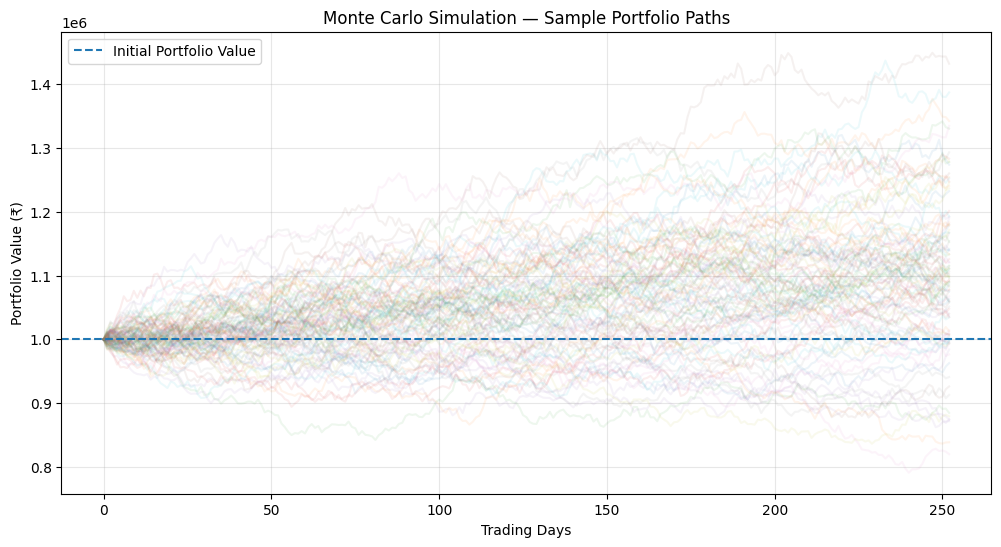

In [ ]:
plt.figure(figsize=(12, 6))

# Plot first 100 simulated paths
plt.plot(
    portfolio_paths_with_initial[:100].T,
    alpha=0.08
)

plt.axhline(
    INITIAL_VALUE,
    linestyle="--",
    label="Initial Portfolio Value"
)

plt.title("Monte Carlo Simulation — Sample Portfolio Paths")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value (₹)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Final Porfolio Value

In [ ]:
final_values = portfolio_paths[:, -1]

final_returns = (
    final_values / INITIAL_VALUE
) - 1

print("Final portfolio values calculated.")
print(f"Mean final value: ₹{final_values.mean():,.2f}")
print(f"Minimum final value: ₹{final_values.min():,.2f}")
print(f"Maximum final value: ₹{final_values.max():,.2f}")

Final portfolio values calculated.
Mean final value: ₹1,096,052.38
Minimum final value: ₹722,358.79
Maximum final value: ₹1,710,402.01


##Calculate Portfolio Statistics

In [ ]:
mean_return = final_returns.mean()
median_return = np.median(final_returns)
std_return = final_returns.std()

best_return = final_returns.max()
worst_return = final_returns.min()

print("Monte Carlo Portfolio Statistics")
print("=" * 45)

print(f"Expected 1-Year Return : {mean_return:.2%}")
print(f"Median 1-Year Return  : {median_return:.2%}")
print(f"Return Volatility      : {std_return:.2%}")
print(f"Best Simulated Return  : {best_return:.2%}")
print(f"Worst Simulated Return : {worst_return:.2%}")

Monte Carlo Portfolio Statistics
Expected 1-Year Return : 9.61%
Median 1-Year Return  : 9.02%
Return Volatility      : 11.78%
Best Simulated Return  : 71.04%
Worst Simulated Return : -27.76%


##Annualized Portfolio Volatility

In [ ]:
# Standard deviation of simulated daily portfolio returns
daily_portfolio_volatility = portfolio_daily_returns.std()

# Annualize using sqrt(252)
annualized_volatility = (
    daily_portfolio_volatility * np.sqrt(TRADING_DAYS)
)

print(f"Daily Portfolio Volatility: {daily_portfolio_volatility:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")

Daily Portfolio Volatility: 0.68%
Annualized Volatility: 10.79%


##Calculate 95% Value-at-Risk

In [ ]:
# Loss is positive when portfolio loses money
losses = INITIAL_VALUE - final_values

# 95% VaR
var_95 = np.percentile(losses, 95)

# Equivalent return-based VaR
var_95_return = -np.percentile(final_returns, 5)

print("95% Value-at-Risk")
print("=" * 40)

print(f"VaR 95%: ₹{var_95:,.2f}")
print(f"VaR 95% as percentage: {var_95_return:.2%}")

95% Value-at-Risk
VaR 95%: ₹84,581.54
VaR 95% as percentage: 8.46%


## Now Checking VaR Directly

In [ ]:
loss_probability = np.mean(losses >= var_95)

print(f"Loss probability beyond 95% VaR: {loss_probability:.2%}")

Loss probability beyond 95% VaR: 5.00%


## Ploting Final Portfolio Value Distribution

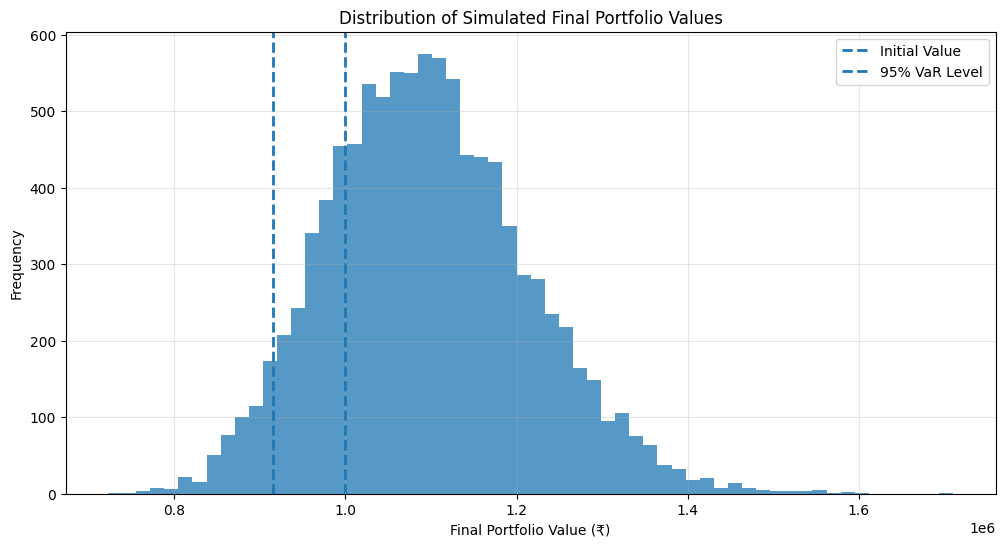

In [ ]:
plt.figure(figsize=(12, 6))

plt.hist(
    final_values,
    bins=60,
    alpha=0.75
)

plt.axvline(
    INITIAL_VALUE,
    linestyle="--",
    linewidth=2,
    label="Initial Value"
)

plt.axvline(
    INITIAL_VALUE - var_95,
    linestyle="--",
    linewidth=2,
    label="95% VaR Level"
)

plt.title("Distribution of Simulated Final Portfolio Values")
plt.xlabel("Final Portfolio Value (₹)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

##Return Distribution

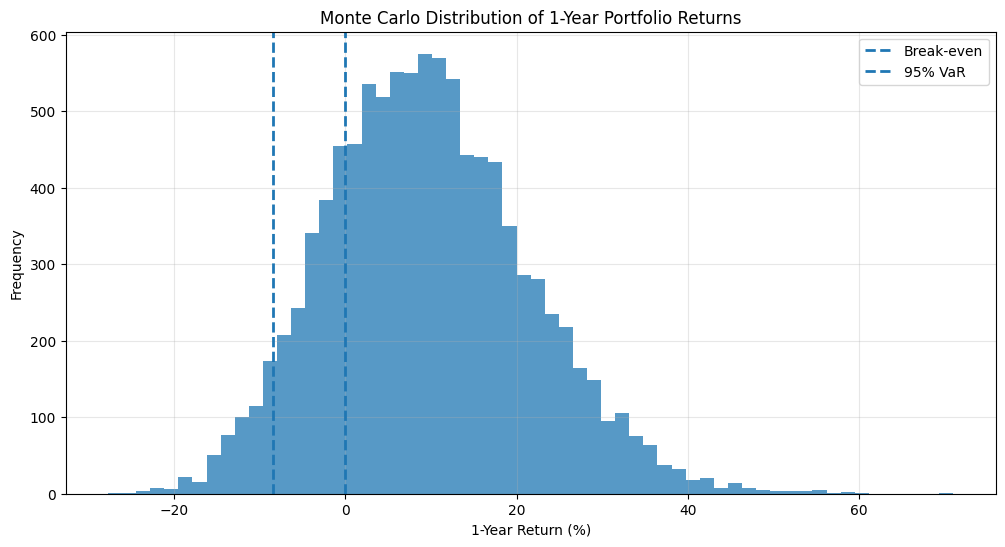

In [ ]:
plt.figure(figsize=(12, 6))

plt.hist(
    final_returns * 100,
    bins=60,
    alpha=0.75
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Break-even"
)

plt.axvline(
    -var_95_return * 100,
    linestyle="--",
    linewidth=2,
    label="95% VaR"
)

plt.title("Monte Carlo Distribution of 1-Year Portfolio Returns")
plt.xlabel("1-Year Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

##Confidence Percentiles

In [ ]:
percentiles = [1, 5, 25, 50, 75, 95, 99]

percentile_values = np.percentile(
    final_returns,
    percentiles
)

percentile_table = pd.DataFrame({
    "Percentile": percentiles,
    "Return": percentile_values
})

percentile_table["Return"] = (
    percentile_table["Return"] * 100
)

percentile_table

,Percentile,Return
0,1,-14.715001
1,5,-8.458154
2,25,1.255704
3,50,9.024406
4,75,17.116615
5,95,29.989653
6,99,39.240493


##Risk Summary Dashboard

In [ ]:
risk_summary = pd.DataFrame({
    "Metric": [
        "Initial Portfolio Value",
        "Number of Simulations",
        "Trading Days",
        "Expected Return",
        "Median Return",
        "Annualized Volatility",
        "Best Return",
        "Worst Return",
        "95% VaR",
        "95% VaR (%)"
    ],
    "Value": [
        f"₹{INITIAL_VALUE:,.0f}",
        f"{N_SIMULATIONS:,}",
        f"{TRADING_DAYS}",
        f"{mean_return:.2%}",
        f"{median_return:.2%}",
        f"{annualized_volatility:.2%}",
        f"{best_return:.2%}",
        f"{worst_return:.2%}",
        f"₹{var_95:,.2f}",
        f"{var_95_return:.2%}"
    ]
})

risk_summary

,Metric,Value
0,Initial Portfolio Value,"₹1,000,000"
1,Number of Simulations,"10,000"
2,Trading Days,252
3,Expected Return,9.61%
4,Median Return,9.02%
5,Annualized Volatility,10.79%
6,Best Return,71.04%
7,Worst Return,-27.76%
8,95% VaR,"₹84,581.54"
9,95% VaR (%),8.46%


##Best & Worst Scenarios

In [ ]:
best_index = np.argmax(final_values)
worst_index = np.argmin(final_values)

print("BEST SIMULATED SCENARIO")
print("-" * 35)
print(f"Final Value: ₹{final_values[best_index]:,.2f}")
print(f"Return: {final_returns[best_index]:.2%}")

print("\nWORST SIMULATED SCENARIO")
print("-" * 35)
print(f"Final Value: ₹{final_values[worst_index]:,.2f}")
print(f"Return: {final_returns[worst_index]:.2%}")

BEST SIMULATED SCENARIO
-----------------------------------
Final Value: ₹1,710,402.01
Return: 71.04%

WORST SIMULATED SCENARIO
-----------------------------------
Final Value: ₹722,358.79
Return: -27.76%


##Asset-Level Statistics

In [ ]:
asset_statistics = pd.DataFrame({
    "Asset": assets,
    "Daily Mean Return": daily_mean,
    "Daily Volatility": daily_volatility,
    "Annualized Mean": daily_mean * TRADING_DAYS,
    "Annualized Volatility": daily_volatility * np.sqrt(TRADING_DAYS),
    "Portfolio Weight": weights
})

asset_statistics

,Asset,Daily Mean Return,Daily Volatility,Annualized Mean,Annualized Volatility,Portfolio Weight
0,Asset A,0.0005,0.012,0.1260,0.190494,0.30
1,Asset B,0.0003,0.015,0.0756,0.238118,0.25
2,Asset C,0.0004,0.010,0.1008,0.158745,0.25
3,Asset D,0.0002,0.018,0.0504,0.285741,0.20


##Correlation Matrix

In [ ]:
# Reshape simulations into a single observation matrix
asset_returns_2d = simulated_returns.reshape(
    -1,
    N_ASSETS
)

correlation_matrix = np.corrcoef(
    asset_returns_2d,
    rowvar=False
)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=assets,
    columns=assets
)

correlation_df

,Asset A,Asset B,Asset C,Asset D
Asset A,1.000000,-0.000500,-0.000688,-0.000710
Asset B,-0.000500,1.000000,-0.000342,-0.000480
Asset C,-0.000688,-0.000342,1.000000,-0.000557
Asset D,-0.000710,-0.000480,-0.000557,1.000000


##Correlation Heatmap

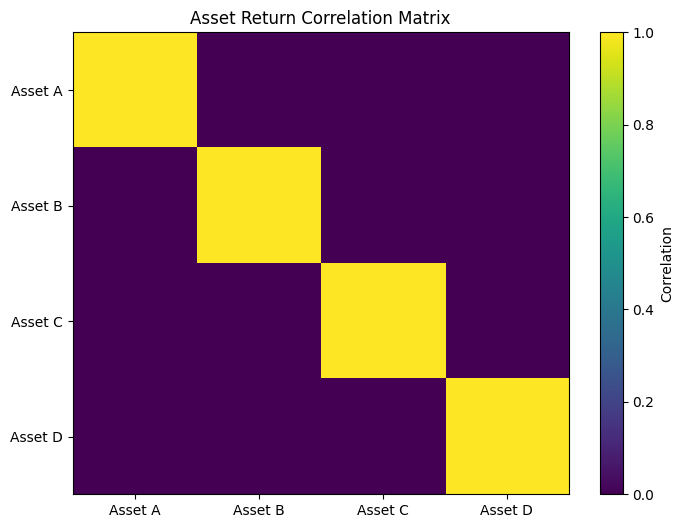

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(N_ASSETS),
    assets
)

plt.yticks(
    range(N_ASSETS),
    assets
)

plt.title("Asset Return Correlation Matrix")

plt.show()

##Monte Carlo Path Statistics

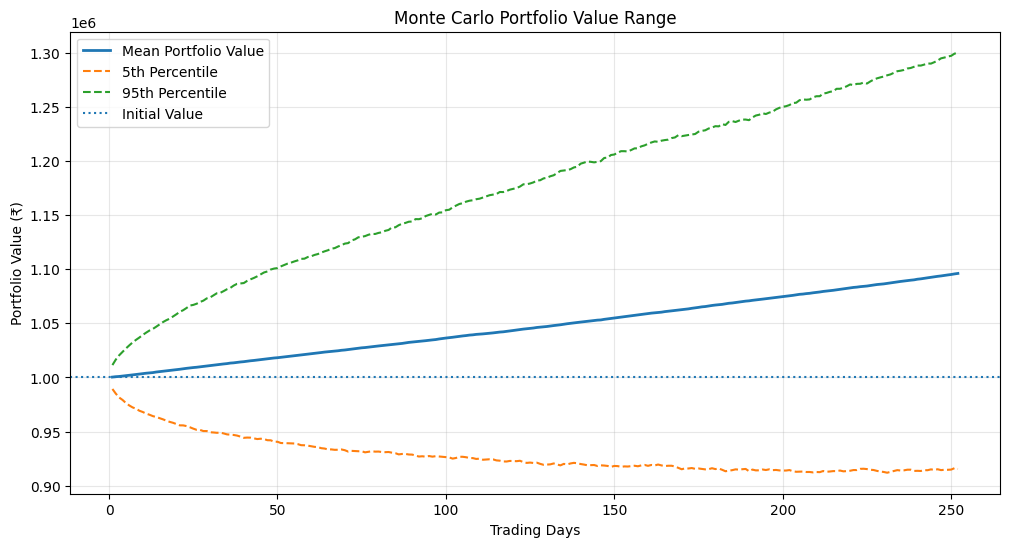

In [ ]:
# Average portfolio value at every trading day
mean_path = portfolio_paths.mean(axis=0)

# 5th percentile path
lower_path = np.percentile(
    portfolio_paths,
    5,
    axis=0
)

# 95th percentile path
upper_path = np.percentile(
    portfolio_paths,
    95,
    axis=0
)

days = np.arange(1, TRADING_DAYS + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    days,
    mean_path,
    linewidth=2,
    label="Mean Portfolio Value"
)

plt.plot(
    days,
    lower_path,
    linestyle="--",
    label="5th Percentile"
)

plt.plot(
    days,
    upper_path,
    linestyle="--",
    label="95th Percentile"
)

plt.axhline(
    INITIAL_VALUE,
    linestyle=":",
    label="Initial Value"
)

plt.title("Monte Carlo Portfolio Value Range")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value (₹)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Adavanced Correlated Asset Simulation

In [ ]:
# Example correlation matrix
correlation = np.array([
    [1.00, 0.40, 0.25, 0.15],
    [0.40, 1.00, 0.30, 0.20],
    [0.25, 0.30, 1.00, 0.35],
    [0.15, 0.20, 0.35, 1.00]
])

# Cholesky decomposition
L = np.linalg.cholesky(correlation)

# Generate independent random shocks
Z = np.random.normal(
    0,
    1,
    size=(N_SIMULATIONS, TRADING_DAYS, N_ASSETS)
)

# Introduce correlation between assets
correlated_shocks = Z @ L.T

# Generate correlated asset returns
correlated_returns = (
    daily_mean
    + daily_volatility * correlated_shocks
)

print(correlated_returns.shape)

(10000, 252, 4)


##Final Automated Report

In [ ]:
print("=" * 65)
print("        MONTE CARLO PORTFOLIO RISK REPORT")
print("=" * 65)

print(f"Initial Portfolio Value : ₹{INITIAL_VALUE:,.2f}")
print(f"Simulations             : {N_SIMULATIONS:,}")
print(f"Trading Days             : {TRADING_DAYS}")
print(f"Number of Assets         : {N_ASSETS}")

print("-" * 65)

print(f"Expected 1-Year Return   : {mean_return:.2%}")
print(f"Median 1-Year Return     : {median_return:.2%}")
print(f"Annualized Volatility    : {annualized_volatility:.2%}")

print("-" * 65)

print(f"Best Simulated Return    : {best_return:.2%}")
print(f"Worst Simulated Return   : {worst_return:.2%}")

print("-" * 65)

print(f"95% VaR                  : ₹{var_95:,.2f}")
print(f"95% VaR Percentage       : {var_95_return:.2%}")

print("=" * 65)

        MONTE CARLO PORTFOLIO RISK REPORT
Initial Portfolio Value : ₹1,000,000.00
Simulations             : 10,000
Trading Days             : 252
Number of Assets         : 4
-----------------------------------------------------------------
Expected 1-Year Return   : 9.61%
Median 1-Year Return     : 9.02%
Annualized Volatility    : 10.79%
-----------------------------------------------------------------
Best Simulated Return    : 71.04%
Worst Simulated Return   : -27.76%
-----------------------------------------------------------------
95% VaR                  : ₹84,581.54
95% VaR Percentage       : 8.46%


##Compare Independent vs Correlated Risk

In [ ]:
# Portfolio returns using correlated asset returns
correlated_portfolio_returns = correlated_returns @ weights

# Annualized volatility
correlated_daily_vol = correlated_portfolio_returns.std()

correlated_annual_vol = (
    correlated_daily_vol * np.sqrt(TRADING_DAYS)
)

print("Independent Simulation")
print(f"Annualized Volatility: {annualized_volatility:.2%}")

print("\nCorrelated Simulation")
print(f"Annualized Volatility: {correlated_annual_vol:.2%}")

Independent Simulation
Annualized Volatility: 10.79%

Correlated Simulation
Annualized Volatility: 14.44%


#**Conclusion**

The Monte Carlo Portfolio Risk Simulator generated 10,000 possible
one-year outcomes for a diversified 4-asset portfolio.

The simulation demonstrates how random daily returns can be used to
estimate future portfolio values and investment risk.

The major results calculated were:

- Expected 1-year portfolio return
- Median portfolio return
- Annualized portfolio volatility
- Best and worst simulated outcomes
- 95% Value-at-Risk
- Distribution of possible portfolio values
- Asset return correlations

Monte Carlo simulation is useful because it does not produce only
one predicted future. Instead, it generates thousands of possible
scenarios and analyzes their distribution.

The 95% VaR provides an estimate of the potential portfolio loss
under the simulated return assumptions.